In [12]:
import sys
if not '../..' in sys.path:
    sys.path.append('../..')
    sys.path.append('..')
from analysis import collection, analysis, emg, plot, model
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib import patches, lines
from pathlib import Path
import numpy as np
import seaborn as sns
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.mixture import BayesianGaussianMixture
from joblib import dump, load
from analysis.offsets import offsets
from numpy.random import default_rng
from scipy.stats import multivariate_normal
from analysis import analysis, model

mpl.rcParams.update(mpl.rcParamsDefault)
mpl.rcParams.update({'axes.labelsize': 16})
mpl.rcParams.update({'figure.figsize': (16*0.8,9*0.8)})
mpl.rcParams.update({'axes.facecolor': "white"})
mpl.rcParams.update({'lines.marker': "+"})
mpl.rcParams.update({'lines.linestyle': ""})
mpl.rcParams.update({"axes.spines.left":   True})
mpl.rcParams.update({"axes.spines.bottom": True})
mpl.rcParams.update({"axes.spines.top":    False})
mpl.rcParams.update({"axes.spines.right":  False})

image_path = Path("/Users/spencer/phd/phd/images/more_results/gmms/")

%matplotlib inline

## multivariate normals

In [2]:
s1 = numpy.random.multivariate_normal(numpy.zeros(64),numpy.eye(64),(5000,))
s2 = numpy.random.multivariate_normal(numpy.zeros(64),numpy.eye(64)*10,(5000,))

In [2]:
# _ = plt.plot(s1)
# _ = plt.plot(s2)

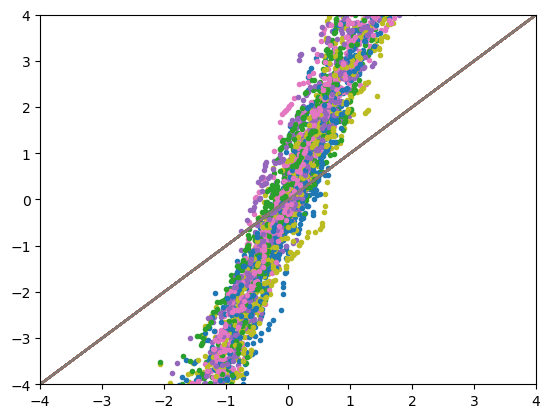

In [4]:
for i in range(64):
    sorted_1 = np.sort(s1[i,:])
    sorted_2 = np.sort(s2[i,:])
    plt.ylim([-4,4])
    plt.xlim([-4,4])
    # plt.plot([numpy.min(sorted_1),numpy.max(sorted_1)], [numpy.min(sorted_2),numpy.max(sorted_2)],"k--")
    plt.plot(sorted_1,sorted_2,'.')
    plt.plot([-4,4],[-4,4])

## mixtures

In [5]:
N = 64
n_cmpts = 8
weights = [1/n_cmpts for _ in range(n_cmpts)]
means = [numpy.ones(shape=(N))*i*10 for i in range(n_cmpts+1)]
covs = [numpy.eye(N) for _ in range(n_cmpts)]

gmm1 = GaussianMixture(n_components=n_cmpts,)
gmm1.weights_ = numpy.array(weights)
gmm1.means_ = numpy.array(means)
gmm1.covariances_ = numpy.array(covs)
samples1, labels = gmm1.sample(5000)

gmm2 = GaussianMixture(n_components=n_cmpts,)
gmm2.weights_ = numpy.array(weights)
gmm2.means_ = numpy.array(means)
gmm2.covariances_ = numpy.array(covs)
samples2, labels = gmm2.sample(5000)

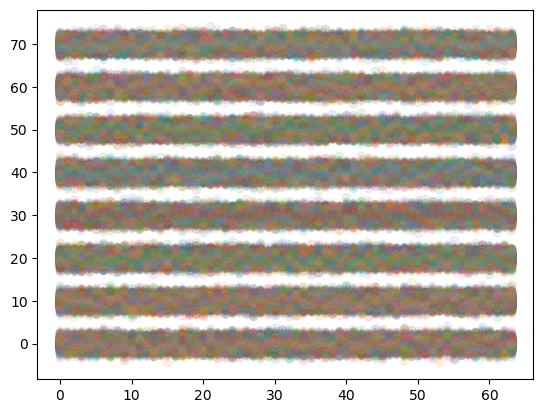

In [6]:
for i in range(5000):
    plt.plot(samples1[i],'-o',alpha=0.1)

In [7]:
samples1.shape, samples2.shape

((5000, 64), (5000, 64))

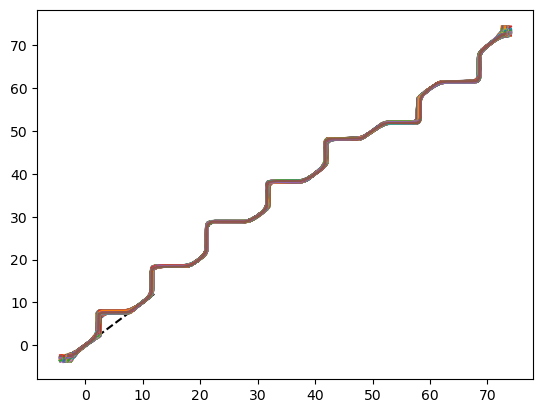

In [8]:
plt.plot([-4,12],[-4,12],'k--')
for i in range(N):
    for j in range(N):
        plt.plot(numpy.sort(samples1[:,i]),numpy.sort(samples2[:,j]))

# real samples

In [9]:
subject_idx = 0

# models
models = model.load_log_trial_models(subject_idx)

# data
stack = analysis.load_trial_stack(subject_idx=subject_idx)

In [10]:
m = models[1]
stack = numpy.log(analysis.remove_nan_rows(stack[9:9+9+1].transpose(0,1,3,2,).reshape(-1,64)))
samples, labels = m.sample(stack.shape[0])

/var/folders/dz/870p8tdx43j5527kzthy65zw0000gn/T/ipykernel_21968/3524350860.py:2: RuntimeWarning: invalid value encountered in log
  stack = numpy.log(analysis.remove_nan_rows(stack[9:9+9+1].transpose(0,1,3,2,).reshape(-1,64)))


Text(0, 0.5, 'Model')

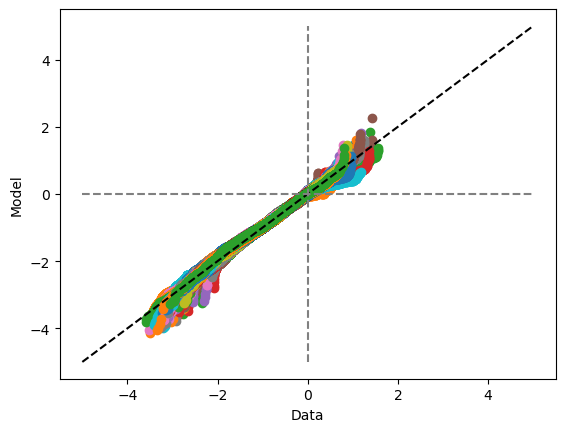

In [11]:
rvalues = []
pvalues = []
for i in range(N):
    if i != 56:
        data_sort = numpy.sort(stack[:,i])
        model_sort = numpy.sort(samples[:,i])
        plt.plot(data_sort,model_sort,'o')
        _, _, r_value, p_value, _ = scipy.stats.linregress(data_sort,model_sort)
        rvalues.append(r_value**2)
        pvalues.append(p_value)
plt.plot([-5,5],[-5,5],'k--')
plt.plot([0,0],[-5,5],'--',color='gray')
plt.plot([-5,5],[0,0],'--',color='gray')
plt.xlabel("Data")
plt.ylabel("Model")

Text(0.5, 1.0, 'R^2 Values')

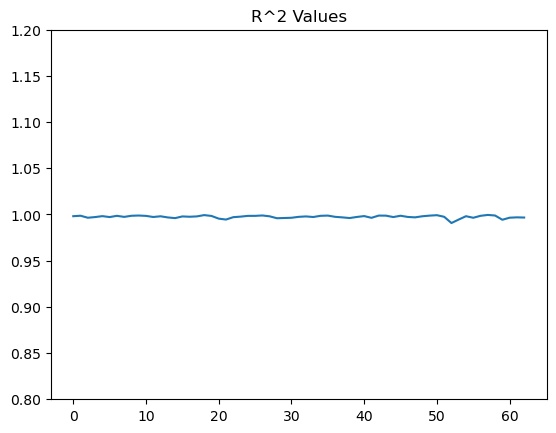

In [12]:
plt.plot(rvalues)
plt.ylim(0.8,1.2)
plt.title("R^2 Values")

In [25]:
chunk_idxs = analysis.make_chunk_indices()

n_dims = 64
rsquareds = []
for subject_idx in range(3):
    # for each subject
    stack = analysis.load_trial_stack(subject_idx=subject_idx)
    models = model.load_log_trial_models(subject_idx)
    
    subject_r_squareds  = []
    for model_idx in range(5):
        # for each model
        m = models[model_idx]
        chunk_idx = chunk_idxs[model_idx]
        substack = numpy.log(analysis.remove_nan_rows(stack[chunk_idx[0]:chunk_idx[1]].transpose(0,1,3,2,).reshape(-1,64)))
        samples, labels = m.sample(substack.shape[0])

        model_rvalues = []
        for i in range(n_dims):
            # for each dimension
            if i != 56:
                data_sort = numpy.sort(substack[:,i])
                model_sort = numpy.sort(samples[:,i])
                # plt.plot(data_sort,model_sort,'o')
                _, _, r_value, p_value, _ = scipy.stats.linregress(data_sort,model_sort)
                model_rvalues.append(r_value**2)

        subject_r_squareds.append(model_rvalues)
    rsquareds.append(subject_r_squareds)
        # plt.plot([-5,5],[-5,5],'k--')
        # plt.plot([0,0],[-5,5],'--',color='gray')
        # plt.plot([-5,5],[0,0],'--',color='gray')
        # plt.xlabel("Data")
        # plt.ylabel("Model")

/var/folders/dz/870p8tdx43j5527kzthy65zw0000gn/T/ipykernel_64913/2180101915.py:15: RuntimeWarning: invalid value encountered in log
  substack = numpy.log(analysis.remove_nan_rows(stack[chunk_idx[0]:chunk_idx[1]].transpose(0,1,3,2,).reshape(-1,64)))


In [26]:
rsquareds = numpy.array(rsquareds)
rsquareds.shape

(3, 5, 63)

{'whiskers': [<matplotlib.lines.Line2D at 0x300457a10>,
 'caps': [<matplotlib.lines.Line2D at 0x300464b50>,
 'boxes': [<matplotlib.lines.Line2D at 0x30043c910>],
 'medians': [<matplotlib.lines.Line2D at 0x300465c50>],
 'fliers': [<matplotlib.lines.Line2D at 0x300464ad0>],
 'means': []}

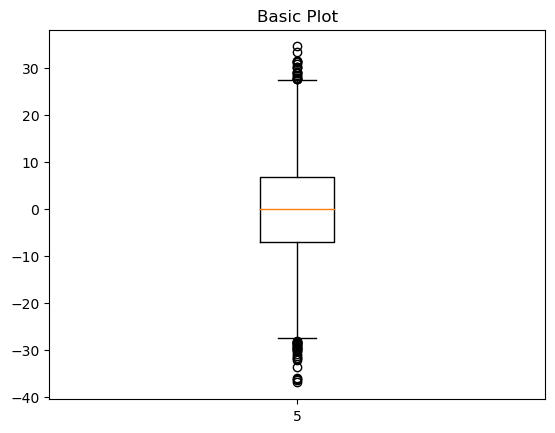

In [35]:
data = numpy.random.normal(0,10,(10000))
fig1, ax1 = plt.subplots()
ax1.set_title('Basic Plot')
ax1.boxplot(data,positions=[5])

In [44]:
(numpy.ones(shape=(d.shape[0],))*i).shape, d[:,i].shape

((189,), (189,))

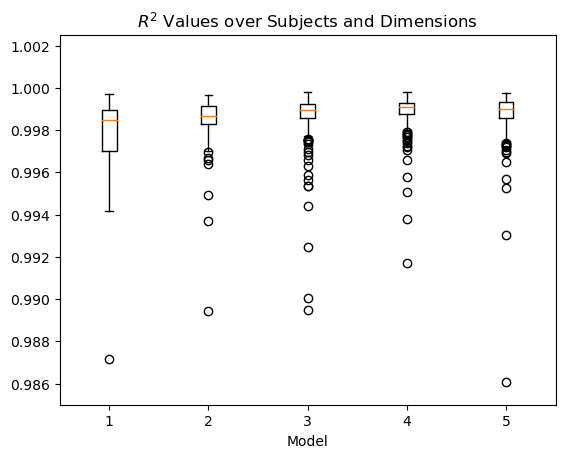

In [63]:
fig1, ax1 = plt.subplots()
ax1.set_title(f'$R^2$ Values over Subjects and Dimensions')
ax1.set_xlabel("Model")
ax1.set_ylim([0.985,1.0025])
d = rsquareds.transpose(0,2,1).reshape(-1,5)
for i in range(5):
    ax1.boxplot(d[:,i].reshape(-1),positions=[i+1])

## log-likelihoods

In [2]:
single_gaussian_scores = []
mixture_scores = []
chunk_idxs = analysis.make_chunk_indices()
for ci, chunk_idx in enumerate(chunk_idxs):
    single_gaussian_scores_over_subjects = []
    mixture_scores_over_subjects = []
    for subject_idx in range(46):
        stack = analysis.load_trial_stack(subject_idx=subject_idx)
        samples = analysis.remove_nan_rows(stack[chunk_idx[0]:chunk_idx[1]].transpose(0,1,3,2).reshape(-1,64))
        samples  = analysis.log_emg_data(samples)

        single_gaussian = BayesianGaussianMixture(n_components=1,
                                                    weight_concentration_prior_type='dirichlet_process',
                                                    weight_concentration_prior=1.0E-8,
                                                    max_iter=300,
                                                    n_init=2,
                                                    warm_start=True,
                                                    random_state=0,
                                                    )
        single_gaussian.fit(samples)
        mixture = model.load_log_trial_models(subject_idx)[ci]

        single_gaussian_scores_over_subjects.append(single_gaussian.score(samples))
        mixture_scores_over_subjects.append(mixture.score(samples))
    
    single_gaussian_scores.append(single_gaussian_scores_over_subjects)
    mixture_scores.append(mixture_scores_over_subjects)

cut 8 samples
cut 25 samples
cut 54 samples
cut 5 samples
cut 52 samples


In [81]:
single_gaussian_scores = np.array(single_gaussian_scores)
mixture_scores = np.array(mixture_scores)
single_gaussian_scores.shape, mixture_scores.shape

((5, 46), (5, 46))

Text(0.5, 0, 'Gaussian Likelihood')

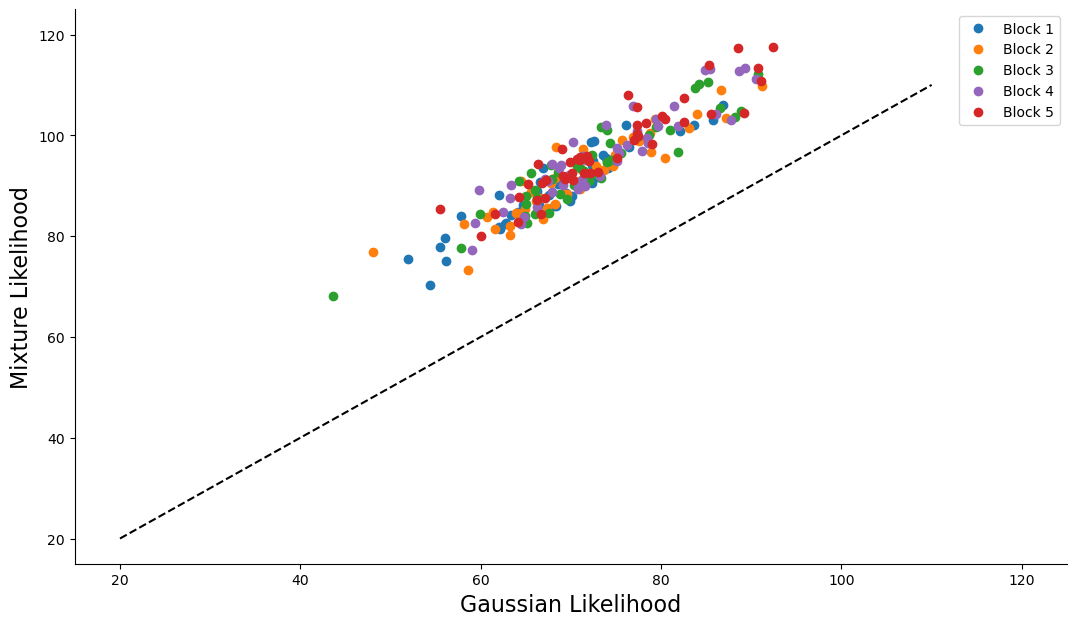

In [82]:
colors = ["tab:blue","tab:orange","tab:green","tab:purple","tab:red"]
handles = []

fig, ax = plt.subplots(1,1)

for i, (s, m) in enumerate(zip(single_gaussian_scores,mixture_scores)):
    h, = plt.plot(s, m, '.', c=colors[i],markersize=12)
    handles.append(h)

# ax.title("Likelihood Comparison")
ax.plot([20,110],[20,110],'k--')
ax.set_xlim([15,125])
ax.set_ylim([15,125])
ax.legend(labels=["Block " + str(i) for i in range(1,6)], handles=handles)
ax.set_ylabel("Mixture Likelihood",fontsize=16)
ax.set_xlabel("Gaussian Likelihood",fontsize=16)

In [83]:
plot.save_figure(fig, "model_likelihood", image_path)

Figure saved to /Users/spencer/phd/phd/images/more_results/gmms/model_likelihood.pdf


In [6]:
# N : number of observations
# k : number of estimated parameters
# AIC = −2 × ln(likelihood) + 2 × k
# BIC = −2 × ln(likelihood) + ln(N) × k

def BIC(m,X):
    D = X.shape[1]
    Df = m.n_components*((D*D - D)/2 + 2*D + 1) - 1
    return (-2 * m.score(X)) + (Df*numpy.log(X.shape[0]))

def AIC(m,X):
    D = X.shape[1]
    Df = m.n_components*((D*D - D)/2 + 2*D + 1) - 1
    return (-2 * m.score(X)) + (2*Df)

# AIC over components

subjects, chunks, components

In [151]:
chunk_idxs = analysis.make_chunk_indices()
components = list(range(1,13,2))
mixture_models = []
for subject_idx in [6]:

    mixture_models_chunks = []
    for ci, chunk_idx in enumerate(chunk_idxs):
        stack = analysis.load_trial_stack(subject_idx=subject_idx)
        samples = analysis.remove_nan_rows(stack[chunk_idx[0]:chunk_idx[1]].transpose(0,1,3,2).reshape(-1,64))
        samples  = analysis.log_emg_data(samples)

        mixture_models_components = []
        for n_cmpts in components:
            print(f"Fitting subject {subject_idx}, chunk {ci}, {n_cmpts} components")
            m = BayesianGaussianMixture(n_components=n_cmpts,
                                                        weight_concentration_prior_type='dirichlet_process',
                                                        weight_concentration_prior=1.0E-8,
                                                        max_iter=300,
                                                        n_init=2,
                                                        warm_start=True,
                                                        random_state=0,
                                                        )
            m.fit(samples)
            mixture_models_components.append(m)

        mixture_models_chunks.append(mixture_models_components)

    mixture_models.append(mixture_models_chunks)

Fitting subject 6, chunk 0, 1 components
Fitting subject 6, chunk 0, 3 components
Fitting subject 6, chunk 0, 5 components
Fitting subject 6, chunk 0, 7 components
Fitting subject 6, chunk 0, 9 components
Fitting subject 6, chunk 0, 11 components
Fitting subject 6, chunk 1, 1 components
Fitting subject 6, chunk 1, 3 components
Fitting subject 6, chunk 1, 5 components
Fitting subject 6, chunk 1, 7 components
Fitting subject 6, chunk 1, 9 components
Fitting subject 6, chunk 1, 11 components
Fitting subject 6, chunk 2, 1 components
Fitting subject 6, chunk 2, 3 components
Fitting subject 6, chunk 2, 5 components
Fitting subject 6, chunk 2, 7 components
Fitting subject 6, chunk 2, 9 components


/opt/homebrew/Caskroom/miniconda/base/envs/data_fix/lib/python3.11/site-packages/sklearn/mixture/_base.py:268: ConvergenceWarning: Initialization 2 did not converge. Try different init parameters, or increase max_iter, tol or check for degenerate data.
  warnings.warn(


Fitting subject 6, chunk 2, 11 components
Fitting subject 6, chunk 3, 1 components
Fitting subject 6, chunk 3, 3 components
Fitting subject 6, chunk 3, 5 components


/opt/homebrew/Caskroom/miniconda/base/envs/data_fix/lib/python3.11/site-packages/sklearn/mixture/_base.py:268: ConvergenceWarning: Initialization 2 did not converge. Try different init parameters, or increase max_iter, tol or check for degenerate data.
  warnings.warn(


Fitting subject 6, chunk 3, 7 components
Fitting subject 6, chunk 3, 9 components
Fitting subject 6, chunk 3, 11 components
Fitting subject 6, chunk 4, 1 components
Fitting subject 6, chunk 4, 3 components
Fitting subject 6, chunk 4, 5 components
Fitting subject 6, chunk 4, 7 components
Fitting subject 6, chunk 4, 9 components
Fitting subject 6, chunk 4, 11 components


In [7]:
# numpy.save("subject_6_models.npy", numpy.array(mixture_models), allow_pickle=True)

# log likelihoods over components

In [74]:
components = list(range(1,13,2)) + [12]
mixture_models = np.load("subject_6_models.npy", allow_pickle=True)
subject_idx = 6
# mixture_models = numpy.load("subject_35_models.npy", allow_pickle=True)
# subject_idx = 35

In [75]:
chunk_idxs = analysis.make_chunk_indices()
scores = []
for subject_models in mixture_models:
    chunk_scores = []
    for ci, chunk_idx in enumerate(chunk_idxs):
        stack = analysis.load_trial_stack(subject_idx=subject_idx)
        samples = analysis.remove_nan_rows(stack[chunk_idx[0]:chunk_idx[1]].transpose(0,1,3,2).reshape(-1,64))
        samples  = analysis.log_emg_data(samples)
        chunk_models = subject_models[ci]
        component_scores = []
        for component_model in chunk_models:
            component_scores.append(component_model.score(samples))
        chunk_scores.append(component_scores)
    scores.append(chunk_scores)
scores = np.array(scores)[0]

In [76]:
scores.shape

(5, 6)

In [77]:
models_12_comps = model.load_log_trial_models(subject_idx)

score12 = []
for ci, chunk_idx in enumerate(chunk_idxs):
        stack = analysis.load_trial_stack(subject_idx=subject_idx)
        samples = analysis.remove_nan_rows(stack[chunk_idx[0]:chunk_idx[1]].transpose(0,1,3,2).reshape(-1,64))
        samples  = analysis.log_emg_data(samples)
        score12.append(models_12_comps[ci].score(samples))

In [78]:
scores = np.hstack([scores, np.array(score12).reshape(5,1)])
scores.shape

(5, 7)

Text(0, 0.5, 'Model Likelihood')

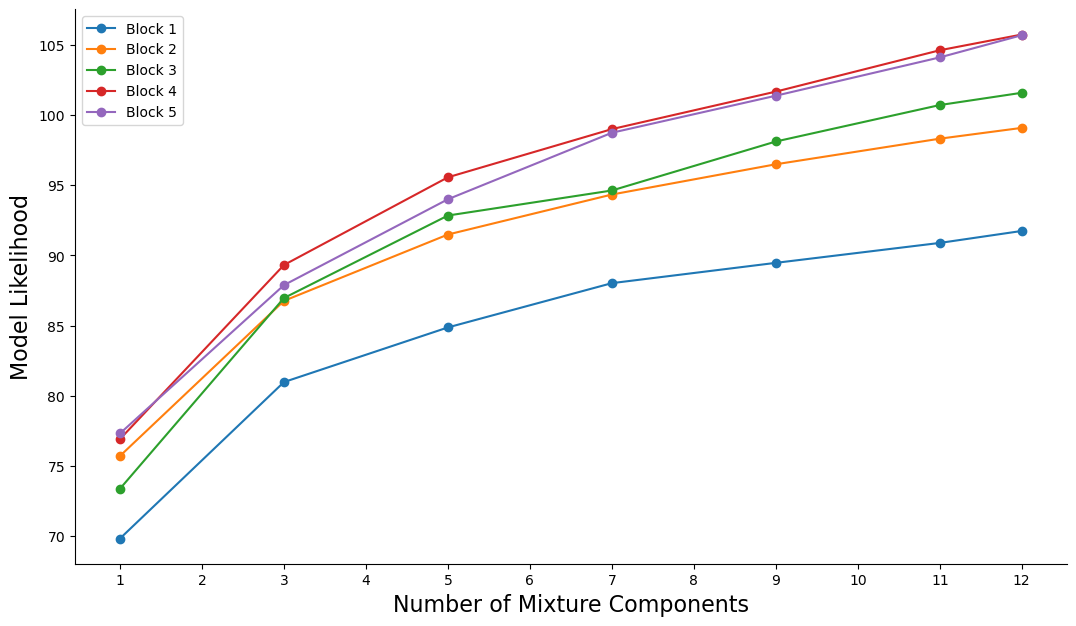

In [79]:
fig, ax = plt.subplots(1,1)
for chunk_i, chunk_scores in enumerate(scores):
    ax.plot(components, chunk_scores,"-o",label=f"Block {chunk_i+1}")
# ax.title("Log Likelihood")
ax.legend()
ax.set_xticks(range(1,13))
ax.set_xlabel("Number of Mixture Components")
ax.set_ylabel("Model Likelihood")

In [80]:
plot.save_figure(fig, "likelihood_over_components", image_path)

Figure saved to /Users/spencer/phd/phd/images/more_results/gmms/likelihood_over_components.pdf


# BIC

In [101]:
single_gaussian_scores = []
mixture_scores = []
for chunk_idx in chunk_idxs:
    single_gaussian_scores_over_subjects = []
    mixture_scores_over_subjects = []
    chunk_idxs = analysis.make_chunk_indices()
    for subject_idx in range(46):
        stack = analysis.load_trial_stack(subject_idx=subject_idx)
        samples = analysis.remove_nan_rows(stack[chunk_idx[0]:chunk_idx[1]].transpose(0,1,3,2).reshape(-1,64))
        samples  = analysis.log_emg_data(samples)

        single_gaussian = BayesianGaussianMixture(n_components=1,
                                                    weight_concentration_prior_type='dirichlet_process',
                                                    weight_concentration_prior=1.0E-8,
                                                    max_iter=300,
                                                    n_init=2,
                                                    warm_start=True,
                                                    random_state=0,
                                                    )
        single_gaussian.fit(samples)
        mixture = model.load_log_trial_models(subject_idx)[0]

        single_gaussian_scores_over_subjects.append(BIC(single_gaussian,samples))
        mixture_scores_over_subjects.append(BIC(mixture,samples))
    
    single_gaussian_scores.append(single_gaussian_scores_over_subjects)
    mixture_scores.append(mixture_scores_over_subjects)

cut 8 samples
cut 25 samples
cut 54 samples
cut 5 samples
cut 52 samples


In [102]:
single_gaussian_scores = numpy.array(single_gaussian_scores)
mixture_scores = numpy.array(mixture_scores)
single_gaussian_scores.shape, mixture_scores.shape

((5, 46), (5, 46))

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


Text(0.5, 0, 'Gaussian BIC')

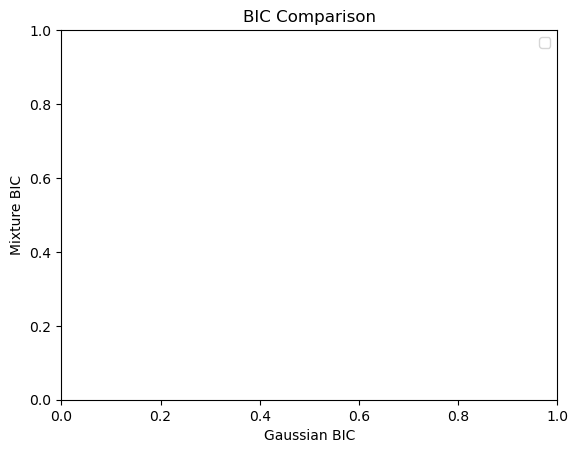

In [106]:
colors = ["r","g","b","k","orange"]
handles = []

for i, (s, m) in enumerate(zip(single_gaussian_scores,mixture_scores)):
    h, = plt.plot(s, m, 'o', c=colors[i])
    handles.append(h)

plt.title("BIC Comparison")
# plt.plot([-1e7,1],[-1e7,1],'k--')
plt.legend(labels=["Block " + str(i) for i in range(1,6)], handles=handles)
plt.ylabel("Mixture BIC")
plt.xlabel("Gaussian BIC")
# plt.ylim([-1.1e7,0.4e7])
# plt.xlim([-1.1e7,0.4e7])

# AIC

In [112]:
single_gaussian_scores = []
mixture_scores = []
chunk_idxs = analysis.make_chunk_indices()
for ci, chunk_idx in enumerate(chunk_idxs):
    single_gaussian_scores_over_subjects = []
    mixture_scores_over_subjects = []
    for subject_idx in range(46):
        stack = analysis.load_trial_stack(subject_idx=subject_idx)
        samples = analysis.remove_nan_rows(stack[chunk_idx[0]:chunk_idx[1]].transpose(0,1,3,2).reshape(-1,64))
        samples  = analysis.log_emg_data(samples)

        single_gaussian = BayesianGaussianMixture(n_components=1,
                                                    weight_concentration_prior_type='dirichlet_process',
                                                    weight_concentration_prior=1.0E-8,
                                                    max_iter=300,
                                                    n_init=2,
                                                    warm_start=True,
                                                    random_state=0,
                                                    )
        single_gaussian.fit(samples)
        mixture = model.load_log_trial_models(subject_idx)[ci]

        single_gaussian_scores_over_subjects.append(AIC(single_gaussian,samples))
        mixture_scores_over_subjects.append(AIC(mixture,samples))
    
    single_gaussian_scores.append(single_gaussian_scores_over_subjects)
    mixture_scores.append(mixture_scores_over_subjects)

cut 8 samples
cut 25 samples
cut 54 samples
cut 5 samples
cut 52 samples


In [113]:
single_gaussian_scores = numpy.array(single_gaussian_scores)
mixture_scores = numpy.array(mixture_scores)
single_gaussian_scores.shape, mixture_scores.shape

((5, 46), (5, 46))

Text(0.5, 0, 'Gaussian BIC')

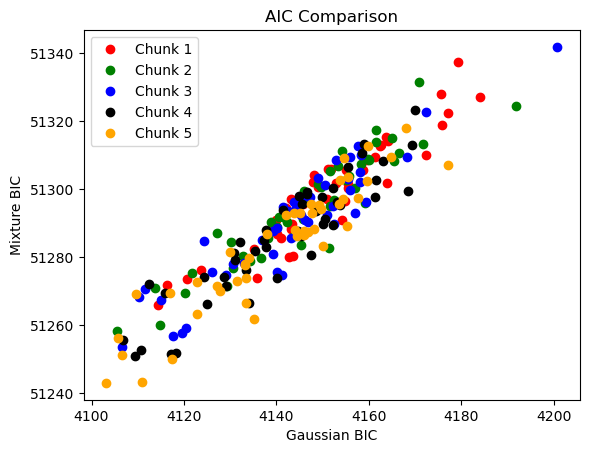

In [119]:
colors = ["r","g","b","k","orange"]
handles = []

for i, (s, m) in enumerate(zip(single_gaussian_scores,mixture_scores)):
    h, = plt.plot(s, m, 'o', c=colors[i])
    handles.append(h)

plt.title("AIC Comparison")
# plt.plot([2e3,5e3],[2e3,5e3],'k--')
plt.legend(labels=["Chunk " + str(i) for i in range(1,6)], handles=handles)
plt.ylabel("Mixture BIC")
plt.xlabel("Gaussian BIC")
# plt.ylim([-1.1e7,0.4e7])
# plt.xlim([-1.1e7,0.4e7])